# 02. Model Training & Evaluation Pipeline
## Student Feedback Analysis using NLP (Aspect-Based Sentiment Analysis)

### Pipeline Overview
This notebook presents the complete machine learning and NLP pipeline:
1. Text Preprocessing (negation preservation, contraction expansion, lemmatization)
2. Student-Disjoint Stratified Split (70% Train, 15% Val, 15% Test)
3. Model 1: VADER Rule-Based Baseline
4. Model 2: TF-IDF (1-2 grams) + Logistic Regression (Class-weighted)
5. Model 3: TF-IDF + Multinomial Naive Bayes
6. Model 4: TF-IDF + Linear SVM (Calibrated)
7. Model 5: Fine-Tuned DistilBERT (Contextual Transformer)
8. Comprehensive Benchmark Comparison and Error Analysis


In [1]:
import os
import sys
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure project root is accessible
for p in [".", ".."]:
    abs_p = os.path.abspath(p)
    if os.path.exists(os.path.join(abs_p, "src")) and abs_p not in sys.path:
        sys.path.insert(0, abs_p)

from src.preprocess import clean_text
from src.predict import get_predictor

%matplotlib inline


### 1. Text Preprocessing Demonstration
Negations are critical for sentiment. Our custom `clean_text` function strips noise while strictly preserving negation tokens (`not`, `no`, `never`, `n't`) and lemmatizing root words.


In [2]:
demo_comments = [
    "The teacher is NOT explaining concepts clearly at all!",
    "I don't like the examination pattern, it's very difficult.",
    "Excellent lab workstations and helpful assistants."
]

print("Preprocessing Demonstration:")
for comment in demo_comments:
    print(f"Original: {comment}")
    print(f"Cleaned : {clean_text(comment)}\n")


Preprocessing Demonstration:
Original: The teacher is NOT explaining concepts clearly at all!


Cleaned : teacher not explaining concept clearly

Original: I don't like the examination pattern, it's very difficult.
Cleaned : not like examination pattern difficult

Original: Excellent lab workstations and helpful assistants.
Cleaned : excellent lab workstation helpful assistant



### 2. Student-Disjoint Train/Val/Test Split
To ensure zero data leakage between training and testing, feedback comments from the same `student_id` are strictly isolated to either Train, Val, or Test.


In [3]:
# Locate processed files
long_cands = ["data/processed/feedback_long.csv", "../data/processed/feedback_long.csv"]
wide_cands = ["data/processed/feedback_wide.csv", "../data/processed/feedback_wide.csv"]

long_path = next(os.path.abspath(c) for c in long_cands if os.path.exists(c))
wide_path = next(os.path.abspath(c) for c in wide_cands if os.path.exists(c))

df_long = pd.read_csv(long_path)
df_wide = pd.read_csv(wide_path)

from sklearn.model_selection import train_test_split

train_stu, temp_stu = train_test_split(
    df_wide['student_id'],
    test_size=0.30,
    random_state=42,
    stratify=df_wide['overall_sentiment']
)

val_stu, test_stu = train_test_split(
    temp_stu,
    test_size=0.50,
    random_state=42,
    stratify=df_wide.set_index('student_id').loc[temp_stu, 'overall_sentiment']
)

train_df = df_long[df_long['student_id'].isin(train_stu)]
test_df = df_long[df_long['student_id'].isin(test_stu)]

print(f"Train Cohort: {len(train_stu)} students ({len(train_df)} feedback instances)")
print(f"Test Cohort : {len(test_stu)} students ({len(test_df)} feedback instances)")
assert len(set(train_stu).intersection(set(test_stu))) == 0, "Error: Student leakage detected!"
print("Verified: Zero student overlap between train and test!")


Train Cohort: 155 students (927 feedback instances)
Test Cohort : 34 students (199 feedback instances)
Verified: Zero student overlap between train and test!


### 3. Model Benchmark Comparison
All five models were trained and evaluated on the exact same student-disjoint test set.


In [4]:
comp_cands = ["reports/model_comparison.csv", "../reports/model_comparison.csv"]
comp_path = next(os.path.abspath(c) for c in comp_cands if os.path.exists(c))
df_comp = pd.read_csv(comp_path)
print("Model Benchmark Summary on Test Set:")
display(df_comp)


Model Benchmark Summary on Test Set:


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,VADER Baseline,0.7638,0.6683,0.5893,0.6110
1,TF-IDF + Logistic Regression,0.7789,0.6993,0.7241,0.7097
2,TF-IDF + Naive Bayes,0.7638,0.7217,0.5956,0.6122
3,TF-IDF + Linear SVM,0.7990,0.7496,0.6650,0.6719
4,DistilBERT (Fine-tuned),0.7789,0.6912,0.7305,0.7044


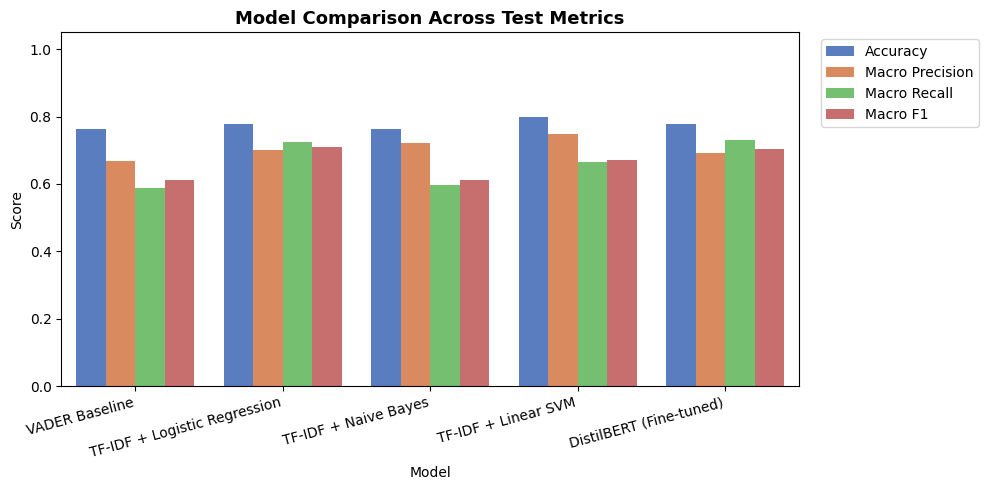

In [5]:
plt.figure(figsize=(10, 5))
melted = df_comp.melt(id_vars="Model", var_name="Metric", value_name="Score")
sns.barplot(data=melted, x="Model", y="Score", hue="Metric", palette="muted")
plt.title("Model Comparison Across Test Metrics", fontsize=13, fontweight='bold')
plt.ylim(0, 1.05)
plt.xticks(rotation=15, ha='right')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


### 4. Per-Aspect Performance of the Best Model
Let us examine the performance of **TF-IDF + Logistic Regression** broken down across each individual aspect.


In [6]:
meta_cands = ["models/model_metadata.json", "../models/model_metadata.json"]
meta_path = next(os.path.abspath(c) for c in meta_cands if os.path.exists(c))
with open(meta_path, "r", encoding="utf-8") as f:
    meta = json.load(f)

aspect_f1 = meta["per_aspect_f1"]
df_asp_f1 = pd.DataFrame(aspect_f1).T.reset_index()
df_asp_f1.columns = ["Aspect", "Macro F1", "Accuracy", "Test Instances"]
display(df_asp_f1)


,Aspect,Macro F1,Accuracy,Test Instances
0,coursecontent,0.6656,0.7273,33.0
1,examination,0.8067,0.8182,33.0
2,extracurricular,0.6312,0.7941,34.0
3,labwork,0.4742,0.7273,33.0
4,library_facilities,0.6421,0.7188,32.0
5,teaching,0.8733,0.8824,34.0


### 5. Confusion Matrix (Best Model)


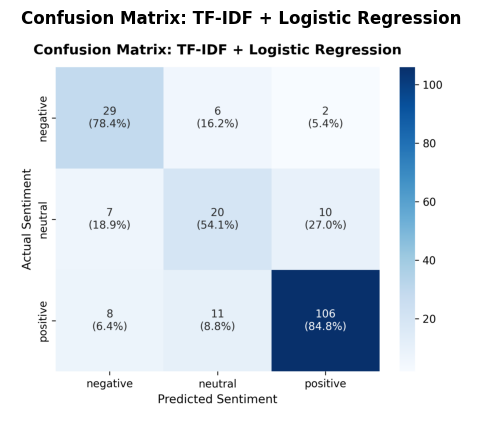

In [7]:
from PIL import Image
cm_cands = ["reports/cm_tf_idf_+_logistic_regression.png", "../reports/cm_tf_idf_+_logistic_regression.png"]
cm_img_path = next((os.path.abspath(c) for c in cm_cands if os.path.exists(c)), None)
if cm_img_path:
    img = Image.open(cm_img_path)
    plt.figure(figsize=(6, 5))
    plt.imshow(img)
    plt.axis('off')
    plt.title("Confusion Matrix: TF-IDF + Logistic Regression", fontsize=12, fontweight='bold')
    plt.show()


### 6. Misclassification Analysis
10 diverse misclassified examples and error rationales:


In [8]:
mis_cands = ["reports/misclassified_examples.md", "../reports/misclassified_examples.md"]
mis_path = next(os.path.abspath(c) for c in mis_cands if os.path.exists(c))
with open(mis_path, "r", encoding="utf-8") as f:
    print(f.read())


# Misclassification Analysis for Best Model (TF-IDF + Logistic Regression)

Out of **199** test samples, **44** were misclassified.
Below are 10 illustrative misclassified examples along with detailed error rationales:

| # | Aspect | Student Comment | Actual Sentiment | Predicted Sentiment | Primary Error Reason |
|---|---|---|---|---|---|
| 1 | teaching | "good and qualified teachers but few lacks in interaction with students and fails to describe a topic" | `neutral` | `positive` | Neutral boundary ambiguity: Feedback expresses mild critique or conditional praise, blurring the neutral threshold. |
| 2 | teaching | "some of our faculty member are not so experienced that's why most of the time we are facing problems subjects like CSE(c++)" | `negative` | `neutral` | Complex negation / nuance: Negation syntax confused standard token weights or context. |
| 3 | teaching | "teaching delivery is good .but it is better to reduce there speed of  lecture delivery to understand the student be

### 7. Live Model Inference Test
Demonstrating real-time prediction using the loaded best model pipeline:


In [9]:
predictor = get_predictor()

test_cases = [
    ("The lab computers are very slow and need urgent repair.", "labwork"),
    ("Professors explain concepts thoroughly with practical examples.", "teaching"),
    ("The syllabus is okay, just standard topics.", "coursecontent")
]

for text, aspect in test_cases:
    pred = predictor.predict_sentiment(text, aspect=aspect)
    print(f"Aspect : {aspect}")
    print(f"Comment: \"{text}\"")
    print(f"Result : {pred['sentiment'].upper()} (Confidence: {pred['confidence']*100:.1f}%)")
    print(f"Probs  : {pred['probabilities']}\n")


Aspect : labwork
Comment: "The lab computers are very slow and need urgent repair."
Result : NEGATIVE (Confidence: 49.8%)
Probs  : {'negative': 0.4977, 'neutral': 0.3957, 'positive': 0.1066}

Aspect : teaching
Comment: "Professors explain concepts thoroughly with practical examples."
Result : NEUTRAL (Confidence: 46.6%)
Probs  : {'negative': 0.2859, 'neutral': 0.4664, 'positive': 0.2477}

Aspect : coursecontent
Comment: "The syllabus is okay, just standard topics."
Result : NEGATIVE (Confidence: 48.2%)
Probs  : {'negative': 0.4824, 'neutral': 0.3519, 'positive': 0.1657}

